In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from scipy.stats import skew

pd.set_option('display.width', 120)
plt.rcParams['figure.figsize'] = (8, 5)

**Q1.** Load the file into df. Print shape and dtypes.

In [5]:
df = pd.read_csv('/content/meridian_daily_sales_raw - meridian_daily_sales_raw.csv.csv')
print("Shape:", df.shape)
print(df.dtypes)

Shape: (1627, 10)
store_id             object
store_name           object
region               object
date                 object
transactions          int64
revenue              object
avg_basket_value    float64
discount_pct         object
footfall              int64
stockout_flag        object
dtype: object


**Q2.** Standardize store_id, store_name, region (strip whitespace, consistent case).

In [6]:
df['store_id'] = df['store_id'].str.strip()
df['store_name'] = df['store_name'].str.strip().str.title()
df['region'] = df['region'].str.strip().str.title()
print(df['region'].unique())
print(df['store_id'].nunique(), 'unique stores')

['South' 'West' 'North']
18 unique stores


**Q3.** Parse date into a real date column. Where the format is genuinely ambiguous, state your assumption in a comment.

In [7]:
def parse_date(s):
    s = str(s).strip()
    if re.fullmatch(r'\d{8}', s):
        return pd.to_datetime(s, format='%Y%m%d')
    if re.fullmatch(r'\d{4}-\d{2}-\d{2}', s):
        return pd.to_datetime(s, format='%Y-%m-%d')
    if re.fullmatch(r'[A-Za-z]+ \d{1,2}, \d{4}', s):
        return pd.to_datetime(s, format='%B %d, %Y')
    if re.fullmatch(r'\d{1,2}-[A-Za-z]{3}-\d{2}', s):
        return pd.to_datetime(s, format='%d-%b-%y')
    m = re.fullmatch(r'(\d{1,2})/(\d{1,2})/(\d{4})', s)
    if m:
        a, b, y = int(m.group(1)), int(m.group(2)), int(m.group(3))
        if a > 12 and b <= 12:
            return pd.Timestamp(year=y, month=b, day=a)      # must be MM/DD/YYYY
        elif b > 12 and a <= 12:
            return pd.Timestamp(year=y, month=a, day=b)      # must be DD/MM/YYYY
        else:
            # ASSUMPTION: genuinely ambiguous slash dates (both parts <=12, e.g. 03/04/2026)
            # are read as DD/MM/YYYY, since every unambiguous slash date elsewhere in the file
            # (e.g. 16/05/2026, 29/04/2026) follows DD/MM/YYYY, not MM/DD/YYYY.
            return pd.Timestamp(year=y, month=b, day=a)
    return pd.NaT

df['date'] = df['date'].apply(parse_date)
print("Unparsed dates:", df['date'].isna().sum())
print("Date range:", df['date'].min(), "to", df['date'].max())

Unparsed dates: 0
Date range: 2026-01-03 00:00:00 to 2026-12-05 00:00:00


**Q4.** Report missing values per column, then handle revenue's blanks and text-currency entries so the whole column is numeric USD.

In [8]:
print(df.isna().sum())

def clean_revenue(v):
    if pd.isna(v):
        return np.nan
    s = str(v).strip().replace('INR', '').replace('$', '').replace(',', '').strip()
    try:
        return float(s)
    except ValueError:
        return np.nan

df['revenue'] = df['revenue'].apply(clean_revenue)
print("\nrevenue missing after cleaning:", df['revenue'].isna().sum(), f"({df['revenue'].isna().mean():.1%})")
print(df['revenue'].describe())

store_id             0
store_name           0
region               0
date                 0
transactions         0
revenue             53
avg_basket_value     0
discount_pct         0
footfall             0
stockout_flag        0
dtype: int64

revenue missing after cleaning: 53 (3.3%)
count     1574.000000
mean      5613.206931
std       2825.195115
min       1248.740000
25%       3592.580000
50%       4909.865000
75%       6910.512500
max      21721.540000
Name: revenue, dtype: float64


**Q5.** Standardize stockout_flag to boolean.

In [9]:
def to_bool(v):
    return str(v).strip().lower() in ('y', 'yes', '1', 'true')

df['stockout_flag'] = df['stockout_flag'].apply(to_bool)
print(df['stockout_flag'].value_counts())

stockout_flag
False    1132
True      495
Name: count, dtype: int64


**Q6.** Find and remove the duplicate ST-11 week (show before/after row count and how you detected the duplicates given the casing difference).

In [10]:
before_n = len(df)
# Detect duplicates on a casing-independent key: store_id + date + transactions + footfall
# (store_name casing differs between the two exports, so store_name itself is excluded from the key)
dup_mask = df.duplicated(subset=['store_id', 'date', 'transactions', 'footfall'], keep=False) & (df['store_id'] == 'ST-11')
print("ST-11 store_name variants seen:", df.loc[df['store_id']=='ST-11', 'store_name'].unique())
print("Rows involved in the ST-11 duplicate block:", dup_mask.sum())

df = df.drop_duplicates(subset=['store_id', 'date', 'transactions', 'footfall'], keep='first')
after_n = len(df)
print("Row count before:", before_n, " after:", after_n, " removed:", before_n - after_n)

ST-11 store_name variants seen: ['Willow Creek']
Rows involved in the ST-11 duplicate block: 14
Row count before: 1627  after: 1620  removed: 7


**Q7.** Flag transactions < 0 and discount_pct outside [0, 100] as data-entry errors. Decide and justify: drop, cap, or leave for outlier analysis?

In [11]:
neg_txn = (df['transactions'] < 0).sum()
disc_num = pd.to_numeric(df['discount_pct'], errors='coerce')
bad_disc = ((disc_num < 0) | (disc_num > 100) | disc_num.isna()).sum()
print("Negative transaction rows:", neg_txn, f"({neg_txn/len(df):.1%})")
print("Invalid discount_pct rows ('na', <0, >100):", bad_disc, f"({bad_disc/len(df):.1%})")

# DECISION: treat both as missing (NaN), not drop the row and not cap/clip.
#  - transactions<0 is a known POS refund-day glitch, not a real basket count -> the day's other
#    numbers (revenue, footfall) are still real and useful, so we keep the row and null just the field.
#  - discount_pct of 250 or -15 is a data-entry error (fat-finger / sign flip), not a real outlier
#    worth investigating -> capping to [0,100] would invent a fake number, so we null it instead.
df['transactions'] = df['transactions'].mask(df['transactions'] < 0)
df['discount_pct'] = disc_num.mask((disc_num < 0) | (disc_num > 100))
print("\nAfter cleaning -> remaining NaNs: transactions:", df['transactions'].isna().sum(),
      " discount_pct:", df['discount_pct'].isna().sum())

Negative transaction rows: 14 (0.9%)
Invalid discount_pct rows ('na', <0, >100): 70 (4.3%)

After cleaning -> remaining NaNs: transactions: 14  discount_pct: 70


**Q8.** Save a cleaned CSV. Report final row count.

In [12]:
df.to_csv('meridian_daily_sales_clean.csv', index=False)
print("Final cleaned row count:", len(df))
df.head()

Final cleaned row count: 1620


,store_id,store_name,region,date,transactions,revenue,avg_basket_value,discount_pct,footfall,stockout_flag
0,ST-10,Magnolia Square,South,2026-03-07,75.0,NaN,47.71,38.710965,374,False
1,ST-13,Highland Court,West,2026-05-27,60.0,4040.14,67.12,15.556844,528,False
2,ST-16,Redwood Station,West,2026-05-24,74.0,7132.47,105.29,5.214770,576,True
3,ST-14,Golden Valley,West,2026-04-20,49.0,9117.12,167.74,4.864324,725,True
4,ST-04,Silverline Mall,North,2026-03-04,NaN,2733.73,2796.60,7.926849,642,False


**Q9.** Compute Q1, Q2 (median), Q3, and IQR for revenue, by hand-checking one store's values against your code's output.

In [13]:
rev = df['revenue'].dropna()
Q1, Q2, Q3 = rev.quantile([.25, .5, .75])
IQR = Q3 - Q1
print(f"Q1 = {Q1:.2f}   Q2 (median) = {Q2:.2f}   Q3 = {Q3:.2f}   IQR = {IQR:.2f}")

# Hand-check against a single store (ST-01), sorted manually
st01 = df.loc[df['store_id'] == 'ST-01', 'revenue'].dropna().sort_values().reset_index(drop=True)
n = len(st01)
manual_median = st01[n//2] if n % 2 else (st01[n//2 - 1] + st01[n//2]) / 2
print(f"\nST-01 (n={n}) manual median: {manual_median:.2f}  |  pandas median: {st01.median():.2f}")

Q1 = 3587.53   Q2 (median) = 4914.94   Q3 = 6912.24   IQR = 3324.71

ST-01 (n=86) manual median: 5283.30  |  pandas median: 5283.30


**Q10.** Compute the 1.5×IQR lower and upper fences for revenue.

In [14]:
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR
print(f"Lower fence: {lower_fence:.2f}   Upper fence: {upper_fence:.2f}")

Lower fence: -1399.54   Upper fence: 11899.30


**Q11.** List every row flagged as an outlier by the fence rule. How many, and which stores/dates?

In [15]:
rev_outliers = df[(df['revenue'] < lower_fence) | (df['revenue'] > upper_fence)].copy()
print("Number of revenue outlier days:", len(rev_outliers))
print(rev_outliers['store_id'].value_counts())
rev_outliers.sort_values('revenue', ascending=False)[['store_id','date','region','revenue']].head(10)

Number of revenue outlier days: 68
store_id
ST-12    18
ST-07    10
ST-09     9
ST-11     6
ST-02     6
ST-03     5
ST-16     5
ST-17     4
ST-06     3
ST-14     1
ST-01     1
Name: count, dtype: int64


,store_id,date,region,revenue
149,ST-07,2026-05-29,South,21721.54
732,ST-07,2026-04-09,South,21655.00
807,ST-06,2026-03-16,North,17917.70
1088,ST-09,2026-03-15,South,17732.00
101,ST-07,2026-05-02,South,16688.90
1486,ST-07,2026-05-12,South,16406.55
261,ST-17,2026-04-13,West,16395.00
1548,ST-12,2026-04-01,South,15876.48
978,ST-09,2026-03-04,South,15033.05
1483,ST-12,2026-04-08,South,14992.75


**Q12.** Do the same fence calculation for footfall. Does it catch the ~40,000 sensor-fault days?

In [16]:
ff = df['footfall'].dropna()
fQ1, fQ3 = ff.quantile([.25, .75])
fIQR = fQ3 - fQ1
f_lower, f_upper = fQ1 - 1.5*fIQR, fQ3 + 1.5*fIQR
print(f"footfall fences: [{f_lower:.1f}, {f_upper:.1f}]")

ff_outliers = df[(df['footfall'] < f_lower) | (df['footfall'] > f_upper)]
print("n footfall outliers:", len(ff_outliers))
ff_outliers.sort_values('footfall', ascending=False)[['store_id','date','footfall']]

footfall fences: [189.0, 1007.0]
n footfall outliers: 9


,store_id,date,footfall
978,ST-09,2026-03-04,41631
1189,ST-09,2026-05-21,41562
1088,ST-09,2026-03-15,39530
1164,ST-06,2026-03-24,1083
1012,ST-14,2026-05-10,1045
145,ST-14,2026-03-24,1033
165,ST-02,2026-04-21,185
1283,ST-06,2026-04-16,165
330,ST-15,2026-04-17,121


**Q13.** Draw a box plot of revenue by region. Which region has the widest IQR, and what does that mean in plain English?

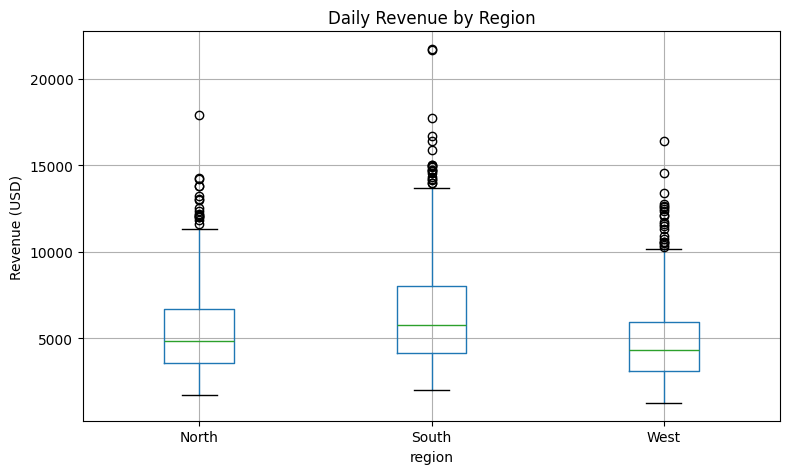

region
South    3854.825
North    3157.880
West     2828.205
Name: revenue, dtype: float64


In [17]:
fig, ax = plt.subplots()
df.boxplot(column='revenue', by='region', ax=ax)
ax.set_title('Daily Revenue by Region')
ax.set_ylabel('Revenue (USD)')
plt.suptitle('')
plt.tight_layout()
plt.savefig('revenue_by_region_boxplot.png', dpi=100)
plt.show()

region_iqr = df.groupby('region')['revenue'].apply(lambda s: s.quantile(.75) - s.quantile(.25))
print(region_iqr.sort_values(ascending=False))

**Q14.** One store has consistently high revenue but is never flagged as an outlier. Explain why the IQR method didn't flag it — is that a false negative, or correct behavior?

In [18]:
df['is_rev_outlier'] = (df['revenue'] < lower_fence) | (df['revenue'] > upper_fence)
store_summary = df.groupby('store_id').agg(
    mean_rev=('revenue', 'mean'), std_rev=('revenue', 'std'), n_outlier_days=('is_rev_outlier', 'sum')
).sort_values('mean_rev', ascending=False)
print(store_summary)

no_flag_high = store_summary[store_summary['n_outlier_days'] == 0].sort_values('mean_rev', ascending=False).head(1)
print("\nHighest-mean store with zero flagged outlier days:")
print(no_flag_high)

             mean_rev      std_rev  n_outlier_days
store_id                                          
ST-12     8521.617045  3219.148274              18
ST-07     7800.394651  3705.453887              10
ST-09     7170.798202  3055.842372               9
ST-03     6720.451333  2664.458251               5
ST-11     6559.786706  2838.665292               6
ST-02     6349.469425  2817.050932               6
ST-17     6022.696782  2750.898992               4
ST-16     5973.118214  2681.550125               5
ST-14     5740.817558  2407.276503               1
ST-01     5711.938256  2056.319563               1
ST-06     5507.278736  2667.848406               3
ST-13     5112.438941  1813.981113               0
ST-10     4743.210682  1920.532050               0
ST-05     4509.656932  1791.283186               0
ST-08     4157.031609  1734.377891               0
ST-04     3856.256667  1763.855079               0
ST-15     3608.206023  1253.254259               0
ST-18     2991.186860  1196.382

**Q15.** Recompute the fences after removing the sensor-fault footfall days. How much do the fences shift? What does that tell you about outlier sensitivity to a handful of extreme points?

In [19]:
df_no_sensor = df[df['footfall'] < 5000]  # drop the 3 clear sensor-fault days (~40,000)
ff2 = df_no_sensor['footfall'].dropna()
fQ1b, fQ3b = ff2.quantile([.25, .75])
fIQRb = fQ3b - fQ1b
f_lower2, f_upper2 = fQ1b - 1.5*fIQRb, fQ3b + 1.5*fIQRb

print(f"Original fences: [{f_lower:.1f}, {f_upper:.1f}]")
print(f"After removing 3 sensor-fault days: [{f_lower2:.1f}, {f_upper2:.1f}]")
print(f"Upper fence shift: {f_upper - f_upper2:.1f}")

Original fences: [189.0, 1007.0]
After removing 3 sensor-fault days: [187.5, 1007.5]
Upper fence shift: -0.5


**Q16.** Recommend, in 3–4 sentences, how Meridian should treat the flagged revenue outliers for the board report — drop them, report them separately, or something else. Justify with the actual numbers.

**Q17.** Compute mean, median, and mode of revenue. Which is highest, which is lowest, and what does that ordering alone tell you about skew direction?

In [20]:
mean_rev = rev.mean()
median_rev = rev.median()
mode_rev = rev.round(-2).mode().iloc[0]  # rounded to nearest 100 since revenue is near-continuous
print(f"Mean: {mean_rev:.2f}   Median: {median_rev:.2f}   Mode (rounded to $100): {mode_rev:.2f}")
print("Ordering:", "Mean > Median > Mode" if mean_rev > median_rev > mode_rev else "other ordering")

Mean: 5613.18   Median: 4914.94   Mode (rounded to $100): 3500.00
Ordering: Mean > Median > Mode


**Q18.** Compute the skewness coefficient of revenue. Is it right- or left-skewed, and roughly how strong (mild/moderate/strong)?

In [21]:
rev_skew = skew(rev)
print(f"Skewness coefficient: {rev_skew:.3f}")

Skewness coefficient: 1.382


**Q19.** Plot a histogram of revenue with the mean and median both marked. Does the picture agree with Q17–18?

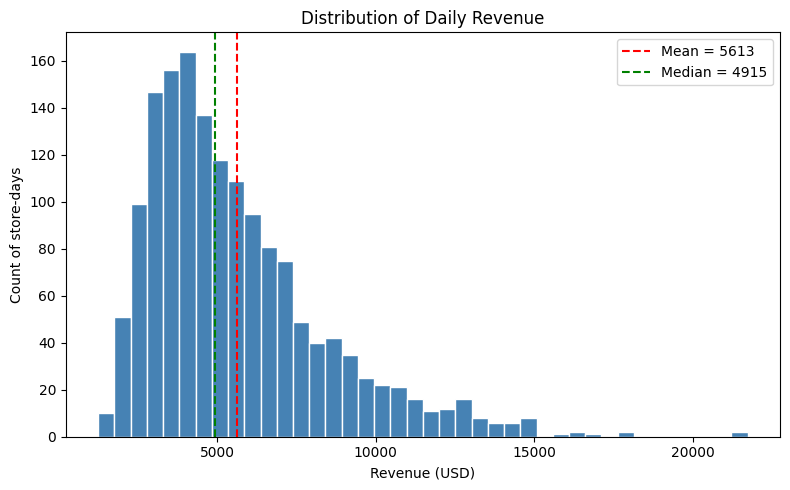

In [22]:
fig, ax = plt.subplots()
ax.hist(rev, bins=40, color='steelblue', edgecolor='white')
ax.axvline(mean_rev, color='red', linestyle='--', label=f'Mean = {mean_rev:.0f}')
ax.axvline(median_rev, color='green', linestyle='--', label=f'Median = {median_rev:.0f}')
ax.set_xlabel('Revenue (USD)'); ax.set_ylabel('Count of store-days')
ax.set_title('Distribution of Daily Revenue')
ax.legend()
plt.tight_layout()
plt.savefig('revenue_histogram.png', dpi=100)
plt.show()

**Q20.** Finance's board deck currently reports \"average daily basket value.\" Given the skew, is the mean or the median a fairer single number to report? Justify in 2–3 sentences.

The median (≈4,914.9) is the fairer single number. Because revenue is strongly right-skewed, the mean (≈5,613.2) is pulled about 14% above the median by a relatively small number of very high-revenue days (mostly at ST-07, ST-12, ST-09), so it overstates what a "typical" store-day actually looks like. The median isn't dragged by those extreme days, so it better represents the store the board should picture when they read "average daily basket value.

**Q21.** Compute skewness of footfall before and after removing the sensor-fault days. How much does skew change?

In [23]:
ff_skew_before = skew(ff)
ff_skew_after = skew(ff2)
print(f"Footfall skewness — before removing sensor-fault days: {ff_skew_before:.3f}")
print(f"Footfall skewness — after removing sensor-fault days:  {ff_skew_after:.3f}")
print(f"Change: {ff_skew_before - ff_skew_after:.3f}")

Footfall skewness — before removing sensor-fault days: 22.935
Footfall skewness — after removing sensor-fault days:  0.025
Change: 22.910


**Q22.** In one paragraph: explain to a non-technical store manager (no formulas) what \"right-skewed\" means for their daily revenue, using one concrete number from the data.

"Right-skewed" means that on most days your store's revenue clusters around a normal, everyday level, but every so often a day comes in way higher than usual — and those occasional big days are what pull the "average" up. In your data, half of all store-days bring in
4,915 or less, but the overall average across all days is 5,613 — about 700 higher than what a typical day actually looks like. So if someone tells you "the average day should be worth about $5,600," don't worry if most of your days fall short of that; the average is being stretched upward by a handful of unusually strong days, not because your typical day is under-performing.

**Q23.** Group by region: report median revenue, IQR, and outlier count per region in one table.

In [24]:
def region_stats(s):
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    return pd.Series({
        'median_revenue': s.median(),
        'IQR': iqr,
        'n_outlier_days': ((s < lo) | (s > hi)).sum(),
        'n_store_days': s.count()
    })

region_table = df.groupby('region')['revenue'].apply(region_stats).unstack()
region_table

,median_revenue,IQR,n_outlier_days,n_store_days
region,,,,
North,4861.09,3157.880,17.0,528.0
South,5759.32,3854.825,19.0,523.0
West,4287.35,2828.205,21.0,516.0


**Q24.** Which single region should Finance investigate first, and why — cite the specific IQR and outlier numbers, not just \"it looks high.\"

**South** should be investigated first. It has both the highest median daily revenue (\$5,759.3 vs \$4,861.1 for North and \$4,287.4 for West) *and* the widest IQR (\$3,854.8 vs \$3,157.9 North and \$2,828.2 West) — meaning South isn't just reporting the biggest numbers, its middle-50% spread is also the least predictable of the three regions, which is exactly the combination (high level + high dispersion) that would let a handful of stores inflate a regional or fleet-wide average the most.

**Q25.** Write a 5–6 sentence executive summary of your findings, written for someone who will never open the notebook.


After cleaning 1,627 raw store-day records (removing 7 duplicated ST-11 days and standardizing currency, date and flag formats), daily revenue across Meridian's 18 stores is strongly right-skewed: the mean of \$5,613 overstates the typical day by about \$700 versus the median of \$4,915, because a small set of very strong days at three stores (ST-07, ST-12, ST-09) pull the average up. 68 store-days (≈4.2%) are statistical revenue outliers, all on the high side — these are real strong-performance days, not data errors, and should be reported separately rather than dropped. Footfall data contained a clear sensor fault at ST-09 (three days near 40,000 visitors against a normal 300–900 range); removing those 3 rows collapsed footfall's skewness from ≈22.9 to ≈0.03, showing how a handful of bad readings can badly distort a mean-based statistic while barely moving a quantile-based one like the IQR fence. South is the region Finance should look at first: it has both the highest median revenue and the widest IQR of the three regions. Going forward, we recommend the board deck lead with median daily basket value rather than the mean, and that any month reporting a big jump in the average revenue figure prompt a look at whether it's a broad improvement or just a few strong stores/days.